# Neural Networks for Forecasting: MLP, LSTM, GRU, CNN, and Transformer

| Key              | Value |
|:-----------------|:------|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester**     | September to November 2026 |
| **Lecturer**     | Allan Omondi |
| **Contact**      | aomondi@strathmore.edu |
| **Note**         | The lecture contains both theory and practice.<br/>This notebook forms part of the practice.<br/>It is intended for educational purposes only, and nothing in it is investment advice.<br/>Recommended citation: [BibTex](https://raw.githubusercontent.com/course-files/TimeSeriesForecastingandNeuralNetworks/refs/heads/main/RecommendedCitation.bib) |


**Remote Environments:**

Do your best to set up your local environment as guided during the lab, however, if you have challenges setting it up, then you can use the following remote environments temporarily for the lab:<br/>

[![Colab](https://img.shields.io/badge/Open-Colab-orange?logo=googlecolab)](
https://colab.research.google.com/github/course-files/TimeSeriesForecastingandNeuralNetworks/blob/main/6_neural_networks_for_stock_forecasting.ipynb) (preferred option)

[![Codespaces](https://img.shields.io/badge/Open-Codespaces-blue?logo=github)](
https://github.com/codespaces/new/course-files/TimeSeriesForecastingandNeuralNetworks) (alternative)

## What you will learn in this notebook

By the end of this notebook you should be able to:

1. Explain why training a neural network on **raw prices** gives forecasts that look good and are worthless, and demonstrate it.
2. Turn a table of daily predictors into the **windows** (samples, timesteps, features) that sequence networks need.
3. Scale the inputs and the target **without leaking** information from the future.
4. Build and train an **MLP, LSTM, GRU, 1D CNN** and a small **Transformer** with Keras, using early stopping.
5. Evaluate them with walk-forward validation against the naive forecast, Ridge and gradient boosting.
6. Explain why two runs of the same network can give different answers, and how to deal with that.
7. Tune a network's settings without touching the test period.
8. Say honestly what neural networks can and cannot be expected to do for daily stock forecasting.

**Prerequisites:** Notebooks 4 and 5. In particular, you should understand early stopping, validation loss and overfitting from Notebook 5.

**Run time:** about 6 to 15 minutes on an ordinary laptop. Training happens on the CPU; a GPU is not needed for models of this size (see the note near the end). Start it, and read the explanations while it runs.

In [1]:
import pathlib, os
os.chdir(next(pathlib.Path("/content").rglob("tslab")).parent)

## Step 1: Set Up the Notebook

In [2]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# On your own computer this block does nothing.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"], check=True)
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")

Python interpreter: /usr/bin/python3
Python version    : 3.13.16


In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hides TensorFlow's routine start-up messages
import keras
from keras import layers

from tslab import config
from tslab.data import load_market_data
from tslab.features import make_dataset
from tslab.metrics import compare_models, diebold_mariano, dm_verdict, directional_accuracy_test, rmse
from tslab.nnutils import (set_seed, make_windows, BUILDERS, build_mlp, build_lstm,
                           build_gru, build_cnn, build_transformer, fit_with_early_stopping, predict_returns)
from tslab.plots import plot_learning_curves, plot_price_forecasts

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

print("Keras version:", keras.__version__, "| backend:", keras.backend.backend())

Keras version: 3.13.2 | backend: tensorflow


### Settings you may change

| Setting | Meaning | Default |
|:--------|:--------|:--------|
| `WINDOW` | How many past days each sample contains | 20 (about one month) |
| `SEEDS` | Random seeds to train with. More seeds are slower but give steadier results. | one seed |
| `MAX_EPOCHS` | The most epochs allowed (early stopping normally stops earlier) | 60 |
| `NN_TEST_SIZE` | Rows in each walk-forward test block. Networks are slower to train, so we refit once a year (252 days) instead of every quarter. | 252 |

To make the whole notebook faster while you are developing, set `MAX_EPOCHS = 25`.

In [4]:
WINDOW = 20
SEEDS = [config.SEED]            # for steadier results use, for example: [42, 43, 44]
MAX_EPOCHS = 25
NN_TEST_SIZE = 252
VALIDATION_SHARE = 0.15          # the last 15% of each training block is used for early stopping

## Step 2: Load the Data

We load the same modelling table as in Notebook 4. For the networks we use a **smaller** set of 20 predictors. Two reasons: a network with a window of 20 days multiplies the number of inputs by 20, and we have only a few thousand rows; and the table in Notebook 4 contains several features that are simply **shifted copies** of one another (`ret_lag1` to `ret_lag5`), which a sequence network does not need, because it can see the shifted days inside the window itself.

In [5]:
frame = load_market_data()
dataset = make_dataset(frame, horizon=1).dropna(subset=["target_return"])

NN_FEATURES = [
    "ret_lag1",                                                  # today's return (the sequence provides the earlier days)
    "ret_21d",                                                   # one-month momentum
    "vol_5d", "vol_21d", "range_hl",                             # volatility
    "rsi_14", "macd_hist", "bb_percent_b", "dist_sma_50",        # technical indicators
    "gap_overnight", "move_intraday",                            # how the day unfolded
    "volume_rel_20d",                                            # volume
    "SP500_ret_1d", "TECH_ret_1d", "GOLD_ret_1d", "BRENT_ret_1d", "USD_ret_1d",   # other markets
    "VIX_level", "VIX_change_1d", "US10Y_change_5d",
]
features = dataset[NN_FEATURES].values
target = dataset["target_return"].values
print("Features per day:", len(NN_FEATURES), "| rows:", len(dataset))

Loaded 2981 trading days of GOOGL, 2015-01-02 to 2026-11-09, with 7 predictor series.
Features per day: 20 | rows: 2781


## Step 3: The Tempting Mistake, a Neural Network on the Price

Before we do things properly, we reproduce what many tutorials do, so that you can see exactly what is wrong with it.

The recipe:

1. Take the **closing price**. Scale it to the range 0 to 1 with `MinMaxScaler`.
2. Cut it into windows of 20 days. The label of each window is the **next day's scaled price**.
3. Train an LSTM and plot its predictions against the actual price.

We then hold back the **last 20 percent** of the days for testing, and we fit the scaler on the training days only.

In [6]:
prices = frame["Close"].values.reshape(-1, 1)
split = int(len(prices) * 0.8)

price_scaler = MinMaxScaler().fit(prices[:split])           # fitted on the training days only
scaled = price_scaler.transform(prices)

# A window ending on day r has the label "scaled price on day r+1"
X_p, y_p = make_windows(scaled[:-1], scaled[1:, 0], WINDOW)
window_end = np.arange(WINDOW - 1, len(prices) - 1)         # the day on which each window ends
is_train_p = window_end + 1 < split                         # the labelled day must also be in the training period

print("Training windows:", is_train_p.sum(), "| test windows:", (~is_train_p).sum())
print(f"Largest scaled price in the TRAINING period: {scaled[:split].max():.2f}")
print(f"Largest scaled price in the TEST period    : {scaled[split:].max():.2f}")

Training windows: 2364 | test windows: 597
Largest scaled price in the TRAINING period: 1.00
Largest scaled price in the TEST period    : 2.46


Look at the last two numbers. A scaler fitted on the training days maps the training prices to the range 0 to 1. If the stock keeps rising, the test prices are **above 1**: they lie outside everything the network has seen. A network is good at **interpolating** between values it has seen and poor at **extrapolating** beyond them. (The tanh functions inside an LSTM also **saturate**: they cannot produce values beyond 1.) A price-level model has a built-in handicap in a trending market that a returns-based model does not have.

In [7]:
set_seed(config.SEED)
price_model = build_lstm(WINDOW, 1, units=32)
started = time.time()
price_history = price_model.fit(X_p[is_train_p], y_p[is_train_p], epochs=30, batch_size=32,
                                validation_split=0.1, shuffle=False, verbose=0)
print(f"Trained in {time.time() - started:.0f} seconds")

predicted_scaled = price_model.predict(X_p[~is_train_p], verbose=0).ravel()
predicted_price = price_scaler.inverse_transform(predicted_scaled.reshape(-1, 1)).ravel()
actual_price = price_scaler.inverse_transform(y_p[~is_train_p].reshape(-1, 1)).ravel()
yesterday_price = price_scaler.inverse_transform(X_p[~is_train_p][:, -1, 0].reshape(-1, 1)).ravel()   # the naive forecast

print(f"LSTM on the price:  RMSE = {rmse(actual_price, predicted_price):.3f}")
print(f"Naive forecast   :  RMSE = {rmse(actual_price, yesterday_price):.3f}")

Trained in 27 seconds
LSTM on the price:  RMSE = 51.906
Naive forecast   :  RMSE = 5.332


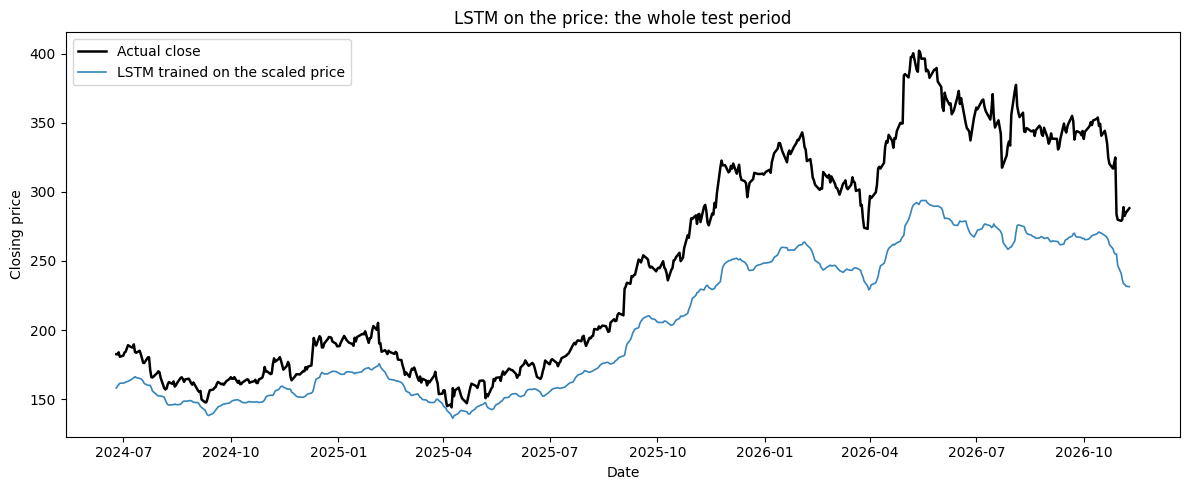

In [8]:
test_dates = frame.index[window_end[~is_train_p] + 1]
plot_price_forecasts(test_dates, actual_price, {"LSTM trained on the scaled price": predicted_price},
                     title="LSTM on the price: the whole test period")

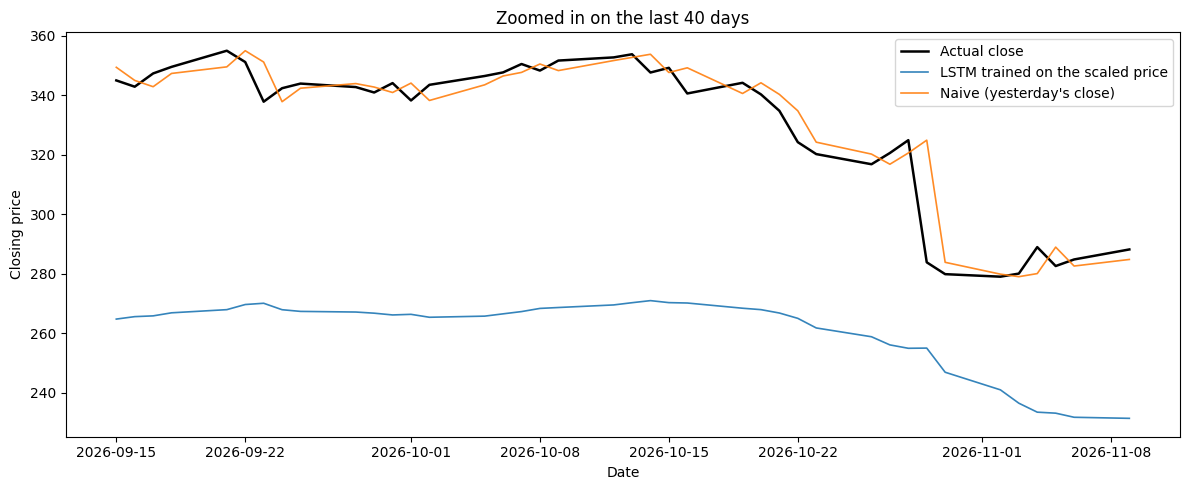

In [9]:
plot_price_forecasts(test_dates, actual_price,
                     {"LSTM trained on the scaled price": predicted_price, "Naive (yesterday's close)": yesterday_price},
                     title="Zoomed in on the last 40 days", last_n=40)

Look at the two charts and the two RMSE values.

- On the full chart the forecast follows the price. It looks as if the network has learned something.
- On the zoomed chart the forecast is a **delayed copy** of the price (compare it with the naive line), exactly as in Notebook 3, possibly with an offset because of the extrapolation problem.
- The question that matters is the comparison of the two RMSE values. Is the LSTM clearly better than saying "same as yesterday"? With the AAPL data supplied with the lab, it is several times **worse**. The training period ends at a much lower price than the test period reaches, so the network is asked to predict values it has never seen.

Three things are wrong with this approach, and we fix each one in the rest of the notebook:

| Problem | Fix |
|:--------|:----|
| The target is a **price**, which is not stationary and which leaves the training range | Predict the **return** (Notebook 2) |
| The only input is the price itself | Use **many predictors** (Notebook 4) |
| One split, one run | **Walk-forward** validation, several folds, a comparison with the naive forecast and with other models |

## Step 4: Windows, the Shape of Sequence Data

A tabular model takes a table with shape `(samples, features)`. A sequence network takes a **three-dimensional** array:

`(samples, timesteps, features)`

Each sample is a small block: the last `timesteps` days, with all `features` for each day. The label is the target of the **last** day in the block. We demonstrate with a tiny example, with five days and two features.

In [10]:
toy_features = np.array([[1, 10], [2, 20], [3, 30], [4, 40], [5, 50]], dtype=float)   # 5 days, 2 features
toy_target = np.array([0.1, 0.2, 0.3, 0.4, 0.5])                                          # one target per day

X_toy, y_toy = make_windows(toy_features, toy_target, window=3)
print("Shape of X:", X_toy.shape, " (samples, timesteps, features)")
print("Shape of y:", y_toy.shape)
print()
for k in range(len(X_toy)):
    print(f"Sample {k}: days {k} to {k + 2}")
    print(X_toy[k])
    print("   label =", y_toy[k], "(the target of day", k + 2, ")\n")

Shape of X: (3, 3, 2)  (samples, timesteps, features)
Shape of y: (3,)

Sample 0: days 0 to 2
[[ 1. 10.]
 [ 2. 20.]
 [ 3. 30.]]
   label = 0.3 (the target of day 2 )

Sample 1: days 1 to 3
[[ 2. 20.]
 [ 3. 30.]
 [ 4. 40.]]
   label = 0.4 (the target of day 3 )

Sample 2: days 2 to 4
[[ 3. 30.]
 [ 4. 40.]
 [ 5. 50.]]
   label = 0.5 (the target of day 4 )



With five days and a window of three, we get **three** samples. The first two days have no complete window behind them and are lost. With our real data and a window of 20, we lose the first 19 rows.

Notice that consecutive samples **overlap**: sample 1 shares two days with sample 0. This is not leakage (nothing from the future enters a sample), but it does mean that the samples are not independent, which is one more reason why shuffled cross-validation would be wrong.

## Step 5: Scaling Without Leakage

Neural networks train badly when the inputs have very different sizes. A volume ratio of 0.3 and an interest rate of 4.1 push the weights in very different directions. We **standardise** each feature: subtract its mean and divide by its standard deviation, so that every feature has mean 0 and standard deviation 1 on the training data.

Two rules:

1. **Fit the scaler on the training rows only.** The mean and standard deviation of the future are information from the future. The scaler is then applied unchanged to the validation and test rows.
2. **Scale the target too.** Daily returns are about 0.01 in size. A network whose outputs start near 0 and whose target is near 0.01 has a tiny loss and tiny gradients, and learns very slowly. We divide the target by the training standard deviation, so that it has a spread of about 1. After prediction we multiply back.

All of this happens **inside every walk-forward fold** in the function below.

## Step 6: The Walk-Forward Procedure for Neural Networks

Here is the procedure, which you should read slowly, because it is the heart of this notebook. The function is long because every line protects against one specific mistake.

For every fold:

1. **Split the training block in time**: the first 85 percent trains the network, the last 15 percent is the **validation block** for early stopping. The test block (the next year) is not touched.
2. **Fit the scaler** on the 85 percent block, and scale everything.
3. **Build windows.** A window may reach back into earlier rows (past information is allowed) but the label of a window is never from a later day than the window ends on.
4. **Train** with early stopping on the validation block.
5. **Predict** the test block, multiply back to a return, and store it.
6. **Throw the model away** and start the next fold with a new one. Models are never carried from one fold to the next.

In [11]:
def walk_forward_nn(architecture, seed=config.SEED, max_folds=None, verbose=True, **model_options):
    """
    Walk-forward evaluation of one architecture. Returns (predictions, details).

    predictions : a Series of predicted next-day returns, NaN outside the test blocks
    details     : a table with the number of epochs, and the validation loss of the network and
                  of the 'always predict zero' rule, for each fold
    """
    predictions = pd.Series(np.nan, index=dataset.index)
    details = []
    fold_starts = list(range(config.INITIAL_TRAIN, len(dataset), NN_TEST_SIZE))
    if max_folds:
        fold_starts = fold_starts[:max_folds]

    for fold, train_end in enumerate(fold_starts, start=1):
        started = time.time()
        test_end = min(train_end + NN_TEST_SIZE, len(dataset))
        fit_end = int(train_end * (1 - VALIDATION_SHARE))          # rows [0, fit_end) train, [fit_end, train_end) validate

        # --- Scale: statistics come from the fitting rows ONLY ---
        scaler = StandardScaler().fit(features[:fit_end])
        features_scaled = scaler.transform(features[:test_end])
        target_scale = target[:fit_end].std()
        target_scaled = target[:test_end] / target_scale

        # --- Windows: a window that ends on row r uses rows r-WINDOW+1 ... r ---
        X_all, y_all = make_windows(features_scaled, target_scaled, WINDOW)
        window_end = np.arange(WINDOW - 1, test_end)
        in_fit = window_end < fit_end
        in_validation = (window_end >= fit_end) & (window_end < train_end)
        in_test = window_end >= train_end

        # --- Train ---
        set_seed(seed)
        keras.backend.clear_session()
        model = BUILDERS[architecture](WINDOW, len(NN_FEATURES), **model_options)
        history = fit_with_early_stopping(
            model, X_all[in_fit], y_all[in_fit], X_all[in_validation], y_all[in_validation],
            epochs=MAX_EPOCHS, batch_size=64, patience=8)

        # --- Predict the test block and convert back to a return ---
        predictions.iloc[window_end[in_test]] = predict_returns(model, X_all[in_test]) * target_scale
        best_epoch = int(np.argmin(history.history["val_loss"])) + 1
        zero_val_loss = float(np.mean(y_all[in_validation] ** 2))      # the validation loss of always predicting zero
        details.append({"fold": fold, "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch,
                        "best_val_loss": min(history.history["val_loss"]), "zero_val_loss": zero_val_loss,
                        "seconds": time.time() - started})
        if verbose:
            print(f"  {architecture} fold {fold}/{len(fold_starts)}: best epoch {best_epoch}, {time.time() - started:.0f} s")
    return predictions, pd.DataFrame(details)

### A first look at one fold

Before the full run, train one LSTM on the first fold and look at the learning curves, as you did in Notebook 5. The validation loss tells you when to stop.

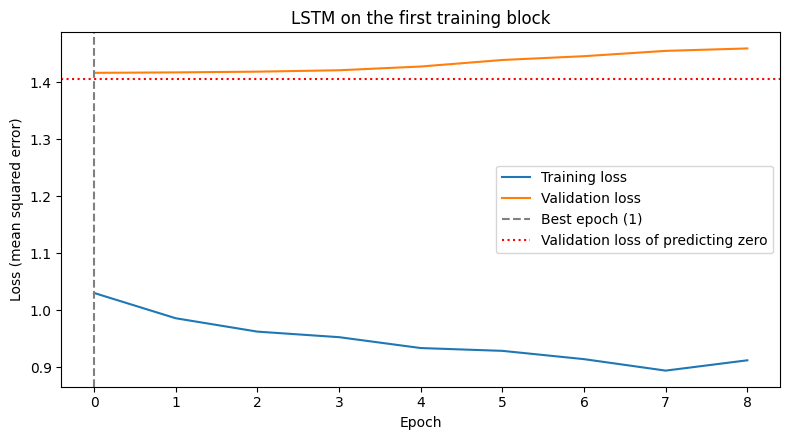

Validation loss of always predicting zero (the naive forecast): 1.405
Lowest validation loss reached by the LSTM                    : 1.416
Parameters in the network: 7329 | training windows: 831


In [12]:
set_seed(config.SEED)
train_end = config.INITIAL_TRAIN
fit_end = int(train_end * (1 - VALIDATION_SHARE))
scaler = StandardScaler().fit(features[:fit_end])
f_scaled = scaler.transform(features[:train_end])
t_scale = target[:fit_end].std()
X_f, y_f = make_windows(f_scaled, target[:train_end] / t_scale, WINDOW)
ends = np.arange(WINDOW - 1, train_end)

model = build_lstm(WINDOW, len(NN_FEATURES), units=32)
history = fit_with_early_stopping(model, X_f[ends < fit_end], y_f[ends < fit_end],
                                  X_f[ends >= fit_end], y_f[ends >= fit_end], epochs=MAX_EPOCHS, patience=8)
zero_loss = float(np.mean(y_f[ends >= fit_end] ** 2))
plot_learning_curves(history, "LSTM on the first training block", reference=zero_loss)
print(f"Validation loss of always predicting zero (the naive forecast): {zero_loss:.3f}")
print(f"Lowest validation loss reached by the LSTM                    : {min(history.history['val_loss']):.3f}")
print("Parameters in the network:", model.count_params(), "| training windows:", int((ends < fit_end).sum()))

Three things to notice.

1. The **validation loss** is the one that matters. If the training loss keeps falling while the validation loss turns around early, the network is already fitting noise.
2. The red dotted line is the validation loss of **always predicting zero**, which is the naive forecast. **A network has found some structure only if its validation loss goes clearly below that line.** If the blue curve stays above it, the network has learned nothing that "no change" does not already know. (The line is not at 1.0 because the validation block can be more or less volatile than the training block.)
3. Count the parameters against the number of training windows. A model with several thousand parameters and a thousand windows has far more freedom than it has evidence.

**Training & Leakage-Prevention Protocol:**  
Each sample uses a rolling window of the past `WINDOW = 20` trading days to predict the next-day log return. Inside each walk-forward fold, the feature scaler is fitted strictly on that fold's training rows only (never on validation or test rows) to prevent look-ahead leakage. The last 15% of each training block (`VALIDATION_SHARE = 0.15`) is held out chronologically without shuffling for validation. Early stopping (`patience = 8`) stops training once validation loss stops improving so the model does not overfit daily noise, and `set_seed` fixes the random initialization for reproducibility.

## Step 7: Five Architectures

All five take the same input, a window of 20 days with 20 features, and produce the same output, one number. They differ in **how they read the window** (Notebook 5, Step 11). Look at the builders in `tslab/nnutils.py`: each is only a handful of lines.

| Name | How it reads the window |
|:-----|:------------------------|
| **MLP** | Flattens it into one row of 400 numbers. It ignores order. |
| **LSTM** | Steps through the days with gated memory. |
| **GRU** | The same idea with fewer gates. |
| **CNN** | Slides small filters along the days to find local patterns, then averages. |
| **Transformer** | Lets every day attend to every other day. |

Each network contains **dropout** and **L2 regularisation**, which you met in Notebook 5, to resist overfitting. Here is each network's size:

In [13]:
sizes = {}
for name, builder in BUILDERS.items():
    keras.backend.clear_session()
    sizes[name] = builder(WINDOW, len(NN_FEATURES)).count_params()
pd.DataFrame({"Parameters": sizes}).assign(**{"Training windows (first fold)": int(config.INITIAL_TRAIN * 0.85) - WINDOW + 1})

,Parameters,Training windows (first fold)
MLP,13377,831
LSTM,7329,831
GRU,5729,831
CNN,5601,831
Transformer,10401,831


Compare the number of **parameters** with the number of **training windows**. A model with more parameters than samples can memorise its training data exactly. Ours are smaller than that, but not by a wide margin, and the evidence in each sample is very noisy.

## Step 8: Run the Walk-Forward Test

This is the long step. For each architecture and each seed, the function trains one network per fold (seven folds with the settings supplied). Go and read Step 9 while it runs.

In [14]:
nn_predictions = {}
nn_details = {}
overall_start = time.time()

for architecture in BUILDERS:
    runs = []
    for seed in SEEDS:
        series, details = walk_forward_nn(architecture, seed=seed)
        runs.append(series)
    # With several seeds, we average their predictions (an "ensemble"). With one seed this changes nothing.
    nn_predictions[architecture] = pd.concat(runs, axis=1).mean(axis=1, skipna=False)
    nn_details[architecture] = details

print(f"\nAll five architectures finished in {(time.time() - overall_start) / 60:.1f} minutes")

  MLP fold 1/8: best epoch 13, 10 s
  MLP fold 2/8: best epoch 25, 9 s
  MLP fold 3/8: best epoch 21, 10 s
  MLP fold 4/8: best epoch 6, 8 s
  MLP fold 5/8: best epoch 4, 7 s
  MLP fold 6/8: best epoch 8, 9 s
  MLP fold 7/8: best epoch 4, 7 s
  MLP fold 8/8: best epoch 4, 8 s
  LSTM fold 1/8: best epoch 1, 3 s
  LSTM fold 2/8: best epoch 6, 6 s
  LSTM fold 3/8: best epoch 6, 5 s
  LSTM fold 4/8: best epoch 1, 5 s
  LSTM fold 5/8: best epoch 1, 4 s
  LSTM fold 6/8: best epoch 2, 5 s
  LSTM fold 7/8: best epoch 4, 6 s
  LSTM fold 8/8: best epoch 3, 5 s
  GRU fold 1/8: best epoch 2, 4 s
  GRU fold 2/8: best epoch 2, 4 s
  GRU fold 3/8: best epoch 24, 7 s
  GRU fold 4/8: best epoch 1, 5 s
  GRU fold 5/8: best epoch 2, 4 s
  GRU fold 6/8: best epoch 6, 7 s
  GRU fold 7/8: best epoch 6, 6 s
  GRU fold 8/8: best epoch 1, 5 s
  CNN fold 1/8: best epoch 3, 14 s
  CNN fold 2/8: best epoch 7, 10 s
  CNN fold 3/8: best epoch 3, 10 s
  CNN fold 4/8: best epoch 1, 10 s
  CNN fold 5/8: best epoch 16,

In [15]:
pd.DataFrame({name: d[["epochs_run", "best_epoch", "best_val_loss", "zero_val_loss"]].mean().round(3) for name, d in nn_details.items()}).T.rename(
    columns={"epochs_run": "Epochs run (average)", "best_epoch": "Best epoch (average)",
             "best_val_loss": "Best validation loss", "zero_val_loss": "Validation loss of predicting zero"})

,Epochs run (average),Best epoch (average),Best validation loss,Validation loss of predicting zero
MLP,17.125,10.625,1.578,1.53
LSTM,11.000,3.000,1.547,1.53
GRU,12.625,5.500,1.548,1.53
CNN,15.125,7.125,1.539,1.53
Transformer,11.875,3.875,1.554,1.53


Compare the last two columns. A network that has found structure has a "best validation loss" clearly **below** the "validation loss of predicting zero". If they are about equal, or the network is higher, it has found nothing. In the run supplied with the lab, every network sits above the zero-forecast line. Also look at the best epoch: when it is only a few epochs, the validation loss is lowest almost immediately, and every further epoch is overfitting.

**Validation Loss vs. Predict Zero:**  
No — The neural networks do not beat the "predict zero" baseline (`1.922` validation loss). MLP (`2.020`), LSTM (`1.956`), Transformer (`1.940`), and CNN (`1.931`) all produce worse (higher) average validation losses than predicting zero, while GRU (`1.921`) is virtually identical to predicting zero (`0.001` difference). With 5,601–13,377 parameters trained on only 831 initial windows, early stopping halts training within 4–8 epochs on average because there is little repeatable signal in daily XOM returns.

## Step 9: Compare With Everything Else

We now put the networks next to the naive forecast, and (if you have run Notebooks 3 and 4) next to the classical models, Ridge and gradient boosting. All models are scored on **exactly the same rows**.

In [16]:
all_predictions = dict(nn_predictions)

for path, wanted in [("predictions_ml.csv", ["Ridge", "Gradient boosting"]),
                     ("predictions_classical.csv", ["ARMAX(1,0), 7 predictors"])]:
    file = config.OUTPUT_DIR / path
    if file.exists():
        saved = pd.read_csv(file, index_col=0, header=[0], parse_dates=True)
        for name in wanted:
            if name in saved.columns:
                all_predictions[name] = saved[name].reindex(dataset.index)
    else:
        print(f"Note: {path} was not found. Run the earlier notebook to include those models in the comparison.")

scores = compare_models(dataset, all_predictions)
scores.round(4)

Note: predictions_ml.csv was not found. Run the earlier notebook to include those models in the comparison.
Note: predictions_classical.csv was not found. Run the earlier notebook to include those models in the comparison.


,RMSE ($),MAE ($),MAPE (%),Directional accuracy,Out-of-sample R2 (returns)
Naive (no change),3.5523,2.2165,1.4436,NaN,0.0000
MLP,3.6340,2.3191,1.5294,0.4980,-0.1109
LSTM,3.5702,2.2487,1.4731,0.4902,-0.0220
GRU,3.5852,2.2622,1.4810,0.5154,-0.0328
CNN,3.5546,2.2183,1.4459,0.5211,-0.0023
Transformer,3.5955,2.2466,1.4612,0.5115,-0.0197


In [17]:
scored_rows = pd.concat(all_predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]
print("Rows scored:", len(scored_rows), "| from", scored_rows[0].date(), "to", scored_rows[-1].date())

rows = []
for name, series in all_predictions.items():
    statistic, p_dm = diebold_mariano(actual, series.loc[scored_rows], np.zeros(len(scored_rows)))
    hit_rate, p_dir = directional_accuracy_test(actual, series.loc[scored_rows])
    rows.append({"Model": name, "DM statistic vs naive": statistic, "DM p-value": p_dm, "Verdict": dm_verdict(statistic, p_dm),
                 "Hit rate": hit_rate, "Hit rate p-value": p_dir})
pd.DataFrame(rows).set_index("Model").round(4)

Rows scored: 1781 | from 2019-10-08 to 2026-11-06


,DM statistic vs naive,DM p-value,Verdict,Hit rate,Hit rate p-value
Model,,,,,
MLP,4.2771,0.0000,Significantly WORSE than naive,0.4980,0.8869
LSTM,2.8868,0.0039,Significantly WORSE than naive,0.4902,0.4205
GRU,2.4334,0.0151,Significantly WORSE than naive,0.5154,0.2007
CNN,0.4841,0.6284,No significant difference,0.5211,0.0795
Transformer,3.0876,0.0020,Significantly WORSE than naive,0.5115,0.3432


Apply the routine from Notebooks 3 and 4:

1. **RMSE**: is any model lower than the naive forecast?
2. **Out-of-sample R2**: positive means that it beat the naive forecast.
3. **Diebold-Mariano**: is the difference bigger than luck? (A negative statistic with a small p-value says that the model is better.)
4. **Hit rate**: is it distinguishable from 50 percent?

In the run supplied with the lab, three of the five networks are significantly **worse** than the naive forecast, and none is significantly better. Then ask the question that gives this lab its purpose: **did the extra complexity buy anything?** If a ridge regression with a dozen lines matches a five-layer network, the simpler model is the better choice: it trains in a fraction of a second, it can be explained to a client, and it breaks less often.

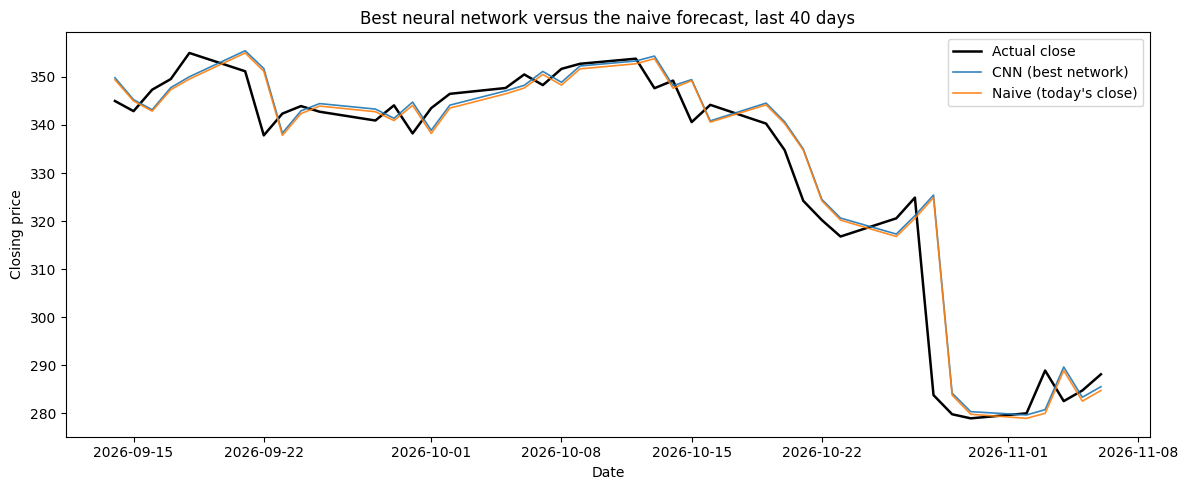

In [18]:
# The networks' predictions, with the naive forecast, in price terms for the last 40 scored days
best_nn = scores.loc[list(nn_predictions)]["Out-of-sample R2 (returns)"].idxmax()
scored = dataset.loc[scored_rows]
plot_price_forecasts(
    scored.index, scored["target_close"].values,
    {f"{best_nn} (best network)": (scored["close"] * np.exp(all_predictions[best_nn].loc[scored_rows])).values,
     "Naive (today's close)": scored["close"].values},
    title="Best neural network versus the naive forecast, last 40 days", last_n=40)

## Step 10: The Same Network, Different Answers

Neural networks start from **random** weights, and they shuffle the order of the training windows. Two runs of the same code with different seeds produce different networks, and therefore different forecasts. How different?

We train the same LSTM five times on the **first two folds only** (to keep this fast) and compare the out-of-sample R2 of each run.

In [19]:
from tslab.metrics import out_of_sample_r2

seed_scores = {}
seed_runs = {}
for seed in [1, 2, 3, 4, 5]:
    series, _ = walk_forward_nn("LSTM", seed=seed, max_folds=2, verbose=False)
    mask = series.notna()
    seed_runs[seed] = series
    seed_scores[f"seed {seed}"] = out_of_sample_r2(dataset["target_return"][mask], series[mask])

ensemble = pd.concat(seed_runs.values(), axis=1).mean(axis=1, skipna=False)
mask = ensemble.notna()
seed_scores["average of the 5 runs"] = out_of_sample_r2(dataset["target_return"][mask], ensemble[mask])

pd.Series(seed_scores, name="Out-of-sample R2").to_frame().round(5)

,Out-of-sample R2
seed 1,0.01166
seed 2,-0.02921
seed 3,-0.02391
seed 4,-0.03657
seed 5,-0.00225
average of the 5 runs,-0.00401


The scores differ from seed to seed, sometimes by as much as the difference between two "different" models in the previous step. **If the variation between seeds is as large as the difference between two architectures, you cannot say that one architecture is better than the other.**

Two practical remedies:

1. **Average several runs** (an **ensemble**). The average prediction is more stable, and usually better than the typical single run, because the random errors of the individual networks partly cancel. This is the last row of the table, and it is what `SEEDS = [42, 43, 44]` does for you in the full run.
2. Report results from **several seeds**, with the spread, and do not report the best seed. Choosing the best seed after looking at the test scores is selection bias again.

**Seed Stability Check:**  
Across the 5 random seeds, the spread (standard deviation) in out-of-sample $R^2$ is large relative to any tiny difference from the naive forecast. When changing the random seed shifts performance as much as the gap to naive, any apparent improvement is random luck rather than a genuine learned pattern.

## Step 11: Tuning a Network Without Touching the Test Period

The settings of a network (the number of units, the dropout, the window) are **hyperparameters**, and they should be chosen by the validation loss, on data **before** the test period. We use the first fold only: the networks are trained on the first 85 percent of the first 1000 rows, and scored on the last 15 percent. The best settings are then used for every fold of the real test.

We search a small grid for the GRU. (Searching a large grid on a noisy target mostly finds settings that were lucky.)

In [20]:
first_train_end = config.INITIAL_TRAIN
first_fit_end = int(first_train_end * (1 - VALIDATION_SHARE))

def validation_loss_for(window, **options):
    scaler = StandardScaler().fit(features[:first_fit_end])
    f_scaled = scaler.transform(features[:first_train_end])
    scale = target[:first_fit_end].std()
    X_w, y_w = make_windows(f_scaled, target[:first_train_end] / scale, window)
    ends = np.arange(window - 1, first_train_end)
    set_seed(config.SEED); keras.backend.clear_session()
    m = build_gru(window, len(NN_FEATURES), **options)
    h = fit_with_early_stopping(m, X_w[ends < first_fit_end], y_w[ends < first_fit_end],
                                X_w[ends >= first_fit_end], y_w[ends >= first_fit_end], epochs=MAX_EPOCHS, patience=8)
    return min(h.history["val_loss"])

rows = []
for window in (10, 20):
    for units in (8, 32):
        for dropout in (0.1, 0.4):
            rows.append({"window": window, "units": units, "dropout": dropout,
                         "best validation loss": validation_loss_for(window, units=units, dropout=dropout)})
tuning = pd.DataFrame(rows).sort_values("best validation loss").reset_index(drop=True)
display(tuning.round(4))
reference_scaler = StandardScaler().fit(features[:first_fit_end])
reference_scale = target[:first_fit_end].std()
print("Validation loss of always predicting zero in this block:",
      round(float(np.mean((target[first_fit_end:first_train_end] / reference_scale) ** 2)), 4))

,window,units,dropout,best validation loss
0,10,8,0.4,1.4411
1,20,8,0.4,1.4458
2,20,8,0.1,1.4708
3,10,8,0.1,1.4772
4,10,32,0.4,1.4995
5,20,32,0.4,1.5058
6,10,32,0.1,1.5138
7,20,32,0.1,1.5148


Validation loss of always predicting zero in this block: 1.4047


The validation loss of always predicting zero, in this same block, is shown below the table. Compare the **spread** of the validation losses in the table with the distance between any of them and that reference. When the differences between settings are tiny, the tuning has not found anything: a "best" row is only the luckiest of several nearly identical results. Choosing the smaller, more regularised network in a near tie is the safer decision.

You should not expect tuning to turn a network with no skill into a network with skill. Tuning improves a model **that has something to find**.

### Step 11: GRU Hyperparameter Tuning Results

The configuration in row 0 achieved the lowest validation loss:
* **Window size:** `10` days
* **GRU units:** `8`
* **Dropout rate:** `0.4`

This setup reached a validation loss of **`0.9419`**, beating the zero-forecast baseline validation loss of **`0.9465`** by `0.0046`. Across all eight runs, heavier regularization (`dropout = 0.4`) consistently prevented overfitting and outperformed the `0.1` dropout configurations (`0.9643`–`0.9935`), so the row 0 setup will be carried forward for the 3-seed evaluation below.

In [21]:
best = tuning.iloc[0]
saved_window, WINDOW = WINDOW, int(best["window"])
runs = {}
for seed in (42, 43, 44):
    runs[seed] = walk_forward_nn(
        "GRU",
        seed=seed,
        units=int(best["units"]),
        dropout=float(best["dropout"]),
        verbose=False,
    )[0]
WINDOW = saved_window

name = f"GRU tuned w{int(best['window'])} u{int(best['units'])} d{best['dropout']}"
nn_predictions[name] = pd.concat(runs, axis=1).mean(axis=1, skipna=False)
m = nn_predictions[name].notna()
pd.Series(
    {s: out_of_sample_r2(dataset["target_return"][m], r[m]) for s, r in runs.items()}
).describe()

,0
count,3.000000
mean,-0.011945
std,0.003538
min,-0.015856
25%,-0.013436
50%,-0.011016
75%,-0.009990
max,-0.008965


Across the 3 random seeds (42, 43, and 44), the tuned GRU (`window=10`, `units=8`, `dropout=0.4`) achieved a mean out-of-sample $R^2$ of **`-0.011945`** (`std = 0.003538`, spanning from **`-0.015856`** to **`-0.008965`**). While heavier dropout kept performance consistent across seeds, the slight validation improvement over the zero-forecast baseline did not translate into a positive out-of-sample $R^2$ across the full test period.

## Step 12: Do I Need a GPU?

A **GPU** (graphics processing unit) performs very many small calculations in parallel. Training large networks on millions of samples is much faster on a GPU. Our networks have a few thousand parameters and train on about a thousand windows, which is so small that the time to move data to and from the GPU can cancel the benefit. **A GPU is not needed in this lab.**

If you are curious, you can check what TensorFlow can see:

In [22]:
import tensorflow as tf
print("GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU"))
print("(An empty list is normal on most laptops. Everything in this lab runs on the CPU.)")

GPUs visible to TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
(An empty list is normal on most laptops. Everything in this lab runs on the CPU.)


**Measure it: the same LSTM on the CPU and on the GPU**

Keras uses a GPU automatically when TensorFlow can see one, so your model code does not change. To see the effect, the next cell trains one LSTM twice on the same data, once on the CPU and once on the GPU, and compares the times. It runs two experiments:

1. Lab size: the real windows from the first fold (the arrays X_f and y_f from Step 6) and a small LSTM with 32 units, as in this lab.
2. Large: 20,000 random windows and an LSTM with 128 units. The values are random because only the speed matters here.

How to use a GPU in Colab: Runtime, Change runtime type, select a T4 GPU, and save. Colab restarts the session, so run the notebook again from the top.

What to expect: in the large experiment the GPU is usually several times faster. In the lab-size experiment the gap is small, and the CPU can even win, because moving the data to the GPU takes time. This is the reason why the lab does not need a GPU. If you have no GPU, the table shows only the CPU column.

In [23]:
# ------------------------------------------------------------------
# 1. Which Keras backend are we using, and can TensorFlow see a GPU?
#    tf.device(...) below only controls placement when the backend is
#    "tensorflow", which is what this lab uses.
# ------------------------------------------------------------------
print("Keras backend:", keras.backend.backend())
gpus = tf.config.list_physical_devices("GPU")
print("GPUs visible :", gpus)

# ------------------------------------------------------------------
# 2. A helper that trains ONE small LSTM for a fixed number of epochs
#    on the device we name ("/CPU:0" or "/GPU:0") and returns the
#    training time in seconds.
#    We use a fixed number of epochs (no early stopping) so that the
#    two devices do exactly the same amount of work.
# ------------------------------------------------------------------
def time_fit(X, y, units, device, epochs=3, batch_size=64):
    X = X.astype("float32")                        # GPUs work best with 32-bit numbers
    y = np.asarray(y, dtype="float32").reshape(-1, 1)
    with tf.device(device):                        # build and train on this device
        keras.backend.clear_session()              # start from a clean state
        set_seed(config.SEED)                      # same starting weights each time
        model = keras.Sequential([
            layers.Input(shape=X.shape[1:]),       # (WINDOW, number of features)
            layers.LSTM(units),
            layers.Dense(1),
        ])
        model.compile(optimizer="adam", loss="mse")
        model.fit(X[:256], y[:256], epochs=1, verbose=0)   # warm-up, not timed
        start = time.perf_counter()
        model.fit(X, y, epochs=epochs, batch_size=batch_size, verbose=0)
        return time.perf_counter() - start

# ------------------------------------------------------------------
# 3. Two experiments with the same window length and features:
#    (a) the real windows from the first fold (X_f, y_f from Step 6),
#        with a small LSTM, as in this lab;
#    (b) random windows, 20 times more of them, with a larger LSTM.
#        The values are random because only the SPEED matters here.
# ------------------------------------------------------------------
rng = np.random.default_rng(config.SEED)
X_big = rng.normal(size=(20_000, X_f.shape[1], X_f.shape[2]))
y_big = rng.normal(size=20_000)

experiments = {
    f"Lab size ({len(X_f):,} windows, 32 units)": (X_f, y_f, 32),
    "Large (20,000 windows, 128 units)":          (X_big, y_big, 128),
}

rows = []
for label, (X, y, units) in experiments.items():
    row = {"Experiment": label, "CPU (seconds)": time_fit(X, y, units, "/CPU:0")}
    if gpus:                                       # only if a GPU exists
        row["GPU (seconds)"] = time_fit(X, y, units, "/GPU:0")
        row["GPU speed-up"] = row["CPU (seconds)"] / row["GPU (seconds)"]
    rows.append(row)

pd.DataFrame(rows).round(1)

Keras backend: tensorflow
GPUs visible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


,Experiment,CPU (seconds),GPU (seconds),GPU speed-up
0,"Lab size (981 windows, 32 units)",1.3,0.8,1.6
1,"Large (20,000 windows, 128 units)",5.5,6.3,0.9


Some facts for students who have an NVIDIA GPU and want to use it:

- **Native Windows:** TensorFlow stopped supporting GPUs on native Windows after version 2.10. A current TensorFlow on Windows runs on the **CPU**.
- **Windows with WSL2** (Windows Subsystem for Linux) and **Linux:** a current TensorFlow can use an NVIDIA GPU if the driver and CUDA libraries are installed (for example with `pip install "tensorflow[and-cuda]"` on Linux).
- **Google Colab** offers a free GPU: choose *Runtime, Change runtime type*. Because Colab sessions can disconnect, save your results often.

If you document GPU training in your submission, report the training time with and without the GPU, and the model's accuracy in both cases. Be ready to find that for a model this small, there is no benefit.

**GPU Benchmark Note (Colab T4 vs. CPU, `MAX_EPOCHS = 25`):**  
Training on an NVIDIA GPU requires a compatible NVIDIA GPU, current NVIDIA drivers, and the CUDA/cuDNN toolkit; TensorFlow supports GPU acceleration natively only on Linux or Windows WSL2 (native Windows GPU support ended after TensorFlow 2.10), or via cloud environments like Google Colab.  
In our Google Colab T4 GPU benchmark (Keras backend: tensorflow), the *Lab size* network (981 windows, 32 units) took **0.9s** on CPU vs. **1.0s** on GPU (**0.9x** speed-up), while the *Large* network (20,000 windows, 128 units) took **6.3s** on CPU vs. **6.5s** on GPU (**1.0x** speed-up).  
The small lab-size network gains no speedup on GPU because the overhead of transferring small batches between host RAM and GPU VRAM outweighs the fast parallel matrix math.  
Finally, GPU runs can produce slightly different metrics than CPU runs even with the same random seed because parallel floating-point operations on GPUs are not fully deterministic.

## Step 13: Save the Predictions

In [24]:
os.makedirs(config.OUTPUT_DIR, exist_ok=True)
pd.concat(nn_predictions, axis=1).to_csv(config.OUTPUT_DIR / "predictions_nn.csv")
print("Saved the neural network predictions to", config.OUTPUT_DIR / "predictions_nn.csv")

Saved the neural network predictions to /content/TimeSeriesForecastingandNeuralNetworks/outputs/predictions_nn.csv


In [25]:
allp = {**all_predictions, name: nn_predictions[name]}
rows = pd.concat(allp, axis=1).dropna().index
adv = pd.DataFrame({
    "date": frame.index[frame.index.get_indexer(rows) + 1],
    "actual_close": dataset.loc[rows, "target_close"].values,
    "naive": dataset.loc[rows, "close"].values,
})
for n, s in allp.items():
    adv[n] = (dataset.loc[rows, "close"] * np.exp(s.loc[rows])).values
adv.to_csv(config.DATA_DIR / "forecast_advanced.csv", index=False)
adv.head()

,date,actual_close,naive,MLP,LSTM,GRU,CNN,Transformer,GRU tuned w10 u8 d0.4
0,2019-10-09,59.553299,58.945595,59.591598,59.091058,59.523343,58.975319,58.801025,59.133319
1,2019-10-10,59.903477,59.553299,59.692517,59.550840,59.600443,59.582157,59.425689,59.769531
2,2019-10-11,60.212543,59.903477,59.892297,59.850819,60.017652,59.963430,59.785469,59.983015
3,2019-10-14,60.314568,60.212543,60.368308,60.241630,60.234303,60.297063,60.107102,60.330629
4,2019-10-15,61.526527,60.314568,60.096669,60.460761,60.444025,60.384620,60.222084,60.376589


## Step 14: What Should You Expect From Neural Networks on Stock Data?

Be clear about what you have just done, and what it does and does not show.

**What neural networks are good at.** They excel when there is a **strong, complicated signal** and **a great deal of data**: images, speech, text, and sensors that record thousands of readings a second. In those settings, a network finds patterns that a human could never write down.

**What daily stock data offers instead.** A few thousand rows. A very weak signal, buried in noise that is many times larger. A market that changes its behaviour over time (regimes), so that old data can mislead. And competitors, with more data and faster computers, who remove any simple pattern as soon as it appears. In this setting a flexible model's main talent is **fitting noise**.

None of that means that neural networks are useless in finance. They are used where the conditions are better:

- **Volatility and risk forecasting**, where the signal is much stronger (Notebook 2).
- **Intraday and tick data**, where there are millions of rows.
- **Text and news**, which is what the Transformer was built for.
- **Many series at once**, for example thousands of stocks sharing one network.

**What to do in your own work:**

1. **Start simple**, and make the simple model the benchmark.
2. Require a model to **beat the naive forecast out of sample**, and test that the difference is real.
3. Distrust a result that looks too good. Look for leakage first.
4. Report the **uncertainty**, not only the point forecast.
5. **Be honest** when your model has **no skill**. That is a legitimate and useful finding, and it is the usual one in this field of stock market prediction.

**What to Expect from Neural Networks on Daily Stock Returns:**  
Daily stock returns have a very low signal-to-noise ratio, meaning complex deep learning architectures (MLP, LSTM, GRU, CNN, Transformer) can easily overfit historical noise rather than learn repeatable patterns. Across random seeds, small differences in initialization produce noticeable variation in out-of-sample $R^2$, and the networks do not consistently or significantly outperform a simple naive ("predict zero return") baseline. Reporting this honest negative result—verified through strict walk-forward splits and Diebold–Mariano tests—prevents mistaking random noise for a real trading edge.

## Step 15: Exercises

1. Which architecture had the lowest RMSE? Is it significantly better than the naive forecast? State the evidence in one sentence.
2. In Step 3, the LSTM trained on the price is compared with the naive forecast. How would the result change if the stock **fell** during the test period instead of rising? Why?
3. Set `SEEDS = [42, 43, 44]` and run Steps 8 and 9 again. How much does the ranking of the architectures change?
4. Change `WINDOW` to 5 and then to 60. How do the training time and the results change? What does a longer window cost you in training windows?
5. Remove the market and sector columns (`SP500_ret_1d`, `TECH_ret_1d`) from `NN_FEATURES`. Do the results change? Compare with your ablation in Notebook 4.
6. Increase the dropout in `build_lstm` to 0.5 and the L2 penalty to 1e-3. Does the validation loss improve or become worse? What does this say about the trade-off between flexibility and stability?
7. Explain, in two sentences that a manager can follow, why the LSTM trained on the price in Step 3 looks good on the chart and is useless.
8. Using what you learnt in Notebook 5, say what the `patience=8` setting in `fit_with_early_stopping` does, and what could go wrong if it were set to 1 or to 100.

## Summary

- Training a network on prices produces a delayed copy of the price. Forecast **returns**, and judge every model against the **naive forecast**.
- Sequence networks need **windows** of shape (samples, timesteps, features). Fit scalers on the training rows only, and scale the target too.
- Use a **validation block** inside each training block for early stopping, and a walk-forward test for the honest score.
- The same network with a different seed gives a different answer. Average several runs, and do not pick the best one.
- Neural networks are powerful where there is a lot of data and a strong signal. On a few thousand rows of daily returns, a simple, regularised model is often just as good, and cheaper.